# 123 · imom vs noimom: blob in the wrong place vs no blob
`base4-v1` (archA, latent 256, rope, norm box_z, 4+4 layers, mask-only, aux box+n_objects, **loss bce_dice_imom**) vs `base4-noimom-v1` (identical, **loss bce_dice**). Context: `archA-v1` (old full loss: BCE + all aux + imom, 2+2 layers, outline) and `s9-t2-ref-vase-200`.
`instance_moment_loss` (src9/utils.py): each pixel goes to its nearest true object (Mahalanobis); the predicted mass in each object's cell is matched to the true log area / 10, centroid and 100 × covariance (L1). The log-area term blows up when predicted mass → 0.

Sample naming: `003091-1` = sample dir `{position:06d}-{speaker}` → position 3091, speaker 1, `2026_10_11_cardboard_four_objs`, eval split **cardboard / cube** (src9 score.sample_dir).

Sections: **1** sample 003091-1 · **2** error taxonomy + shift-invariant IoU · **3** calibration / commitment · **4** encoder (u probe) vs decoder (logits, weights) · **5** summary. fp32, all ep200. Helpers from nb120.

In [1]:
import os, sys, math, re, json
os.environ["TQDM_DISABLE"] = "1"
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src9").exists())
sys.path.insert(0, str(ROOT / "src9")); os.chdir(ROOT)
import dataset as D9, score
from arch.transformer2 import Transformer2
torch.set_num_threads(8); torch.manual_seed(0); np.random.seed(0)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 90, "font.size": 10})
DEV = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cuda.matmul.allow_tf32 = False; torch.backends.cudnn.allow_tf32 = False
GRID = {"imom": "base4-v1", "noimom": "base4-noimom-v1", "archA": "archA-v1", "ref": "s9-t2-ref-vase-200"}
PAIR = ["imom", "noimom"]
COL = {"imom": "tab:red", "noimom": "tab:blue", "archA": "tab:orange", "ref": "tab:green"}
CAT = {(b, s): c for b, cs in D9.CATEGORIES.items() for c, ss in cs.items() for s in ss}
OOD = ["rotated", "cylinder", "unseen-object", "unseen-speaker", "unseen-laser", "lid"]
THR = .08
pd.DataFrame({r: {k: json.load(open(ROOT / "runs" / n / "args.json")).get(k) for k in ("loss", "aux", "outline", "freq_layers", "laser_layers", "readout", "latent_dim", "norm", "pos")} for r, n in GRID.items()}).T

,loss,aux,outline,freq_layers,laser_layers,readout,latent_dim,norm,pos
imom,bce_dice_imom,box_nobj,0,4,4,archA,256,box_z,rope
noimom,bce_dice,box_nobj,0,4,4,archA,256,box_z,rope
archA,None,None,None,2,2,archA,256,None,None
ref,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN


## 0 · load every ep200 eval prediction (4 runs × 4672 samples, keep the probability maps)

In [2]:
NOBJ = {}
def n_objects(exp, sid, pos, spk):
    k = (exp, sid, pos, spk)
    if k not in NOBJ: NOBJ[k] = int(D9.load_meta(score.sample_dir(exp, sid, pos, spk))["n_objects"])
    return NOBJ[k]

def load_eval(run, ep=200):
    rows, P, Yl = [], [], []
    for f in sorted((ROOT / "runs" / run / "outputs_history/eval").glob(f"*/*/ep{ep:04d}-ba*.pt")):
        d = torch.load(f, weights_only=False, map_location="cpu"); p, info = d["mask_pred"].float().numpy(), d["info"]
        box, split = f.parent.parent.name, f.parent.name
        for i in range(len(p)):
            k = (info["experiment"][i], int(info["sample_id"][i]), int(info["position_id"][i]), int(info["speaker"][i]))
            y = score.truth(*k, *p.shape[-2:]) > .5
            if not y.any(): continue
            rows.append(dict(box=box, split=split, group=CAT.get((box, split)), exp=k[0], sid=k[1], pos=k[2], spk=k[3], nobj=n_objects(*k)))
            P.append(p[i]); Yl.append(y)
    return pd.DataFrame(rows), np.stack(P), np.stack(Yl)

KEY = ["box", "split", "exp", "sid", "pos", "spk"]
EV = {r: load_eval(n) for r, n in GRID.items()}
META = EV["imom"][0]
for r in GRID:   # same samples, same order in every run
    assert (EV[r][0][KEY].values == META[KEY].values).all() and (EV[r][2] == EV["imom"][2]).all(), r
YT = EV["imom"][2]; PR = {r: EV[r][1] for r in GRID}
print(len(META), "non-empty eval samples;", META.nobj.value_counts().to_dict(), "objects;", META.group.value_counts().to_dict())

4660 non-empty eval samples; {1: 4350, 2: 310} objects; {'id': 2191, 'unseen-object': 550, 'control': 399, 'cylinder': 331, 'multiple': 310, 'unseen-position': 197, 'unseen-laser': 192, 'rotated': 166, 'unseen-angle': 108, 'unseen-speaker': 85, 'lid': 83, 'unseen-rotated-object': 36, 'broken': 12}


## 1 · sample 003091-1 (cardboard / cube, position 3091, speaker 1)
Top: true mask and each run's probability map (log colour scale so sub-threshold mass shows; white contour = p 0.08, black = true mask). Below: the other three speakers at the same position, and the run-level numbers.

,max_p,sum_p,true_area,area_08,iou_08,mass_in_true,mean_p_in_true,iou_02
imom,1.000,42.839,41.0,55.0,0.000,0.001,0.001,0.000
noimom,0.002,0.016,41.0,0.0,0.000,0.243,0.000,0.000
archA,0.977,31.964,41.0,54.0,0.696,0.824,0.643,0.651
ref,0.996,41.664,41.0,57.0,0.463,0.557,0.566,0.416


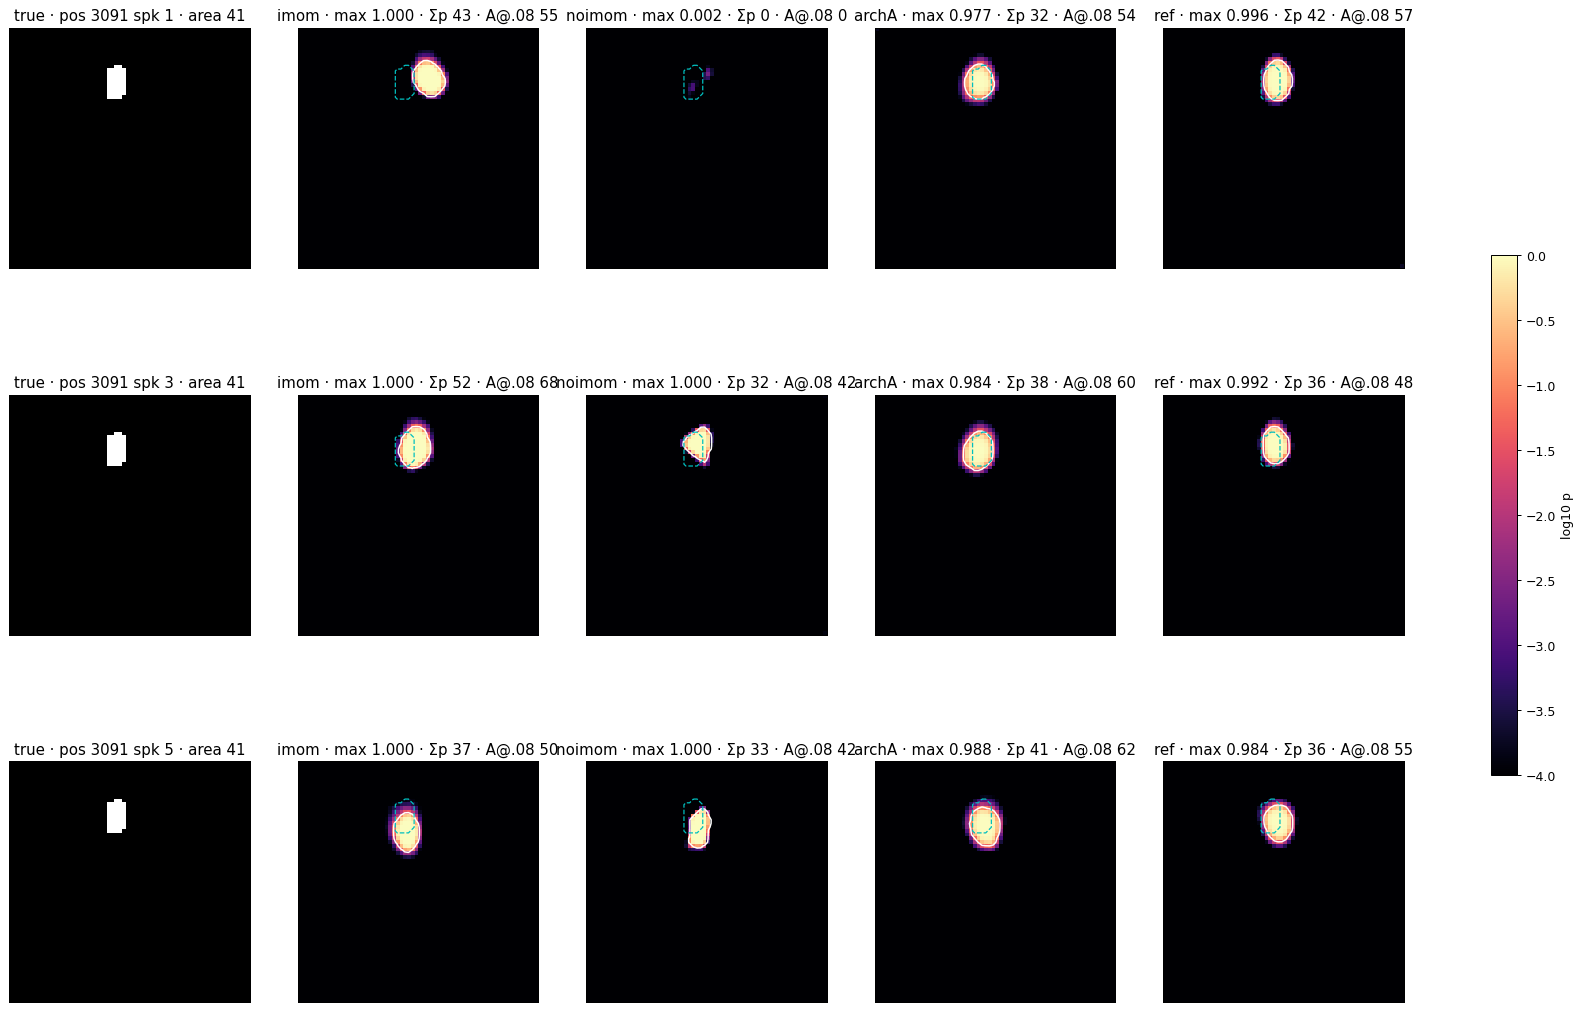

In [3]:
def stats1(p, y):
    b = p > THR
    return dict(max_p=p.max(), sum_p=p.sum(), true_area=y.sum(), area_08=b.sum(), iou_08=(b & y).sum() / max((b | y).sum(), 1),
                mass_in_true=p[y].sum() / max(p.sum(), 1e-9), mean_p_in_true=p[y].mean(), iou_02=((p > .02) & y).sum() / max(((p > .02) | y).sum(), 1))
cub = META[(META.box == "cardboard") & (META.split == "cube") & (META.pos == 3091)].sort_values("spk")
i0 = cub.index[cub.spk == 1][0]
display(pd.DataFrame({r: stats1(PR[r][i0], YT[i0]) for r in GRID}).T.round(3))
fig, axs = plt.subplots(len(cub), 5, figsize=(25, 5 * len(cub)))
for row, i in enumerate(cub.index):
    axs[row, 0].imshow(YT[i], cmap="gray"); axs[row, 0].set_title(f"true · pos 3091 spk {META.spk[i]} · area {YT[i].sum()}")
    for c, r in enumerate(GRID, 1):
        ax = axs[row, c]; p = PR[r][i]
        im = ax.imshow(np.log10(p.clip(1e-4)), vmin=-4, vmax=0, cmap="magma")
        ax.contour(p, [THR], colors="w", linewidths=1.2); ax.contour(YT[i], [.5], colors="c", linewidths=1, linestyles="--")
        ax.set_title(f"{r} · max {p.max():.3f} · Σp {p.sum():.0f} · A@.08 {(p > THR).sum()}")
for ax in axs.flat: ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axs, shrink=.5, label="log10 p"); plt.show()

## 2 · error taxonomy (every non-empty eval sample)
- **miss**: area(p>.08) < 10% of the true area
- **displaced**: area within 0.5–2× true, IoU < .3, and IoU after moving the prediction's CoM onto the true CoM (shape IoU) > .5 → right shape, wrong place
- **good**: IoU ≥ .5 · **other**: the rest (partial, wrong size, wrong shape)

Plus CoM error (px at 64×64) on non-miss samples, and the proposed metric **shift-invariant IoU** = best IoU over integer shifts within ±8 px (computed as a cross-correlation on a padded canvas, so nothing falls off the edge). `shift gain` = siIoU − IoU measures "blob, wrong spot".

In [4]:
def taxonomy(p, Y, thr=THR):
    B = torch.tensor(p > thr); T = torch.tensor(Y)
    ab, at = B.flatten(1).sum(1).float(), T.flatten(1).sum(1).float(); inter = (B & T).flatten(1).sum(1).float()
    iou = inter / (ab + at - inter).clamp_min(1)
    g = torch.stack(torch.meshgrid(torch.arange(64.), torch.arange(64.), indexing="ij"))              # (2,H,W)
    cb = (B[:, None] * g).flatten(2).sum(-1) / ab[:, None].clamp_min(1); ct = (T[:, None] * g).flatten(2).sum(-1) / at[:, None]
    com_err = torch.where(ab > 0, (cb - ct).norm(dim=1), torch.tensor(float("nan")))
    # shape IoU: shift the prediction by round(ct - cb) (zero fill)
    sh = torch.round(ct - cb).long(); shape = torch.zeros(len(B))
    for i in range(len(B)):
        if ab[i] == 0: continue
        dy, dx = sh[i].tolist(); b = B[i]; s = torch.zeros_like(b)
        s[max(dy, 0):64 + min(dy, 0), max(dx, 0):64 + min(dx, 0)] = b[max(-dy, 0):64 + min(-dy, 0), max(-dx, 0):64 + min(-dx, 0)]
        shape[i] = (s & T[i]).sum() / max((s | T[i]).sum(), 1)
    # shift-invariant IoU, ±8 px: inter(shift) = xcorr(pred, true) on a canvas padded by 8
    R = 8; si = []
    for i in range(0, len(B), 512):
        b = F.pad(B[i:i + 512].float().to(DEV), (R,) * 4)[None]; t = T[i:i + 512].float().to(DEV)[:, None]
        it = F.conv2d(b, t, groups=len(t))[0]                                                           # (n,17,17)
        u = ab[i:i + 512, None, None].to(DEV) + at[i:i + 512, None, None].to(DEV) - it
        si.append((it / u.clamp_min(1)).flatten(1).max(1).values.cpu())
    si = torch.cat(si)
    ratio = ab / at
    cls = np.where(ratio.numpy() < .1, "miss", np.where(iou.numpy() >= .5, "good",
                   np.where((ratio.numpy() >= .5) & (ratio.numpy() <= 2) & (iou.numpy() < .3) & (shape.numpy() > .5), "displaced", "other")))
    return pd.DataFrame(dict(iou=iou.numpy(), shape_iou=shape.numpy(), si_iou=si.numpy(), com_err=com_err.numpy(), area_ratio=ratio.numpy(), cls=cls,
                             max_p=p.reshape(len(p), -1).max(1), sum_p=p.reshape(len(p), -1).sum(1), true_area=at.numpy()))

TX = {r: pd.concat([META, taxonomy(PR[r], YT)], axis=1) for r in GRID}
for r in GRID: assert abs(TX[r].iou[TX[r].group.isin(["id", "multiple"])].mean() - TX[r].iou[TX[r].group.isin(["id", "multiple"])].mean()) < 1e-9
print("ID (id+multiple) / OOD IoU@.08 check:", {r: (round(TX[r].iou[TX[r].group.isin(["id", "multiple"])].mean(), 3), round(TX[r].iou[TX[r].group.isin(OOD)].mean(), 3)) for r in GRID})

def summ(t):
    c = t.cls.value_counts(normalize=True)
    nm = t[t.cls != "miss"]
    return {"n": len(t), "IoU@.08": t.iou.mean(), "siIoU ±8": t.si_iou.mean(), "shift gain": (t.si_iou - t.iou).mean(), **{k: c.get(k, 0.) for k in ["good", "miss", "displaced", "other"]},
            "CoM err px (non-miss)": nm.com_err.mean(), "CoM err med": nm.com_err.median(), "shape IoU (non-miss)": nm.shape_iou.mean()}
SUBSETS = {"overall": lambda t: t, "ID (id+multiple)": lambda t: t[t.group.isin(["id", "multiple"])], "unseen-position": lambda t: t[t.group == "unseen-position"],
           "OOD": lambda t: t[t.group.isin(OOD)], "single-object": lambda t: t[t.nobj == 1], "two-object": lambda t: t[t.nobj == 2],
           "cardboard / cube": lambda t: t[(t.box == "cardboard") & (t.split == "cube")], "cube (all boxes)": lambda t: t[t.split == "cube"]}
T2 = pd.DataFrame({(s, r): summ(f(TX[r])) for s, f in SUBSETS.items() for r in GRID}).T
print("T2 · error taxonomy (rates as fractions)"); display(T2.round(3))

ID (id+multiple) / OOD IoU@.08 check: {'imom': (np.float32(0.603), np.float32(0.349)), 'noimom': (np.float32(0.651), np.float32(0.355)), 'archA': (np.float32(0.623), np.float32(0.349)), 'ref': (np.float32(0.679), np.float32(0.377))}
T2 · error taxonomy (rates as fractions)


n  IoU@.08  siIoU ±8  shift gain   good   miss  displaced  other  CoM err px (non-miss)  CoM err med  shape IoU (non-miss)
overall          imom    4660.0    0.513     0.659       0.146  0.604  0.009      0.086  0.302                  3.152        1.629                 0.664
                 noimom  4660.0    0.545     0.655       0.110  0.662  0.052      0.043  0.242                  2.558        1.250                 0.670
                 archA   4660.0    0.527     0.663       0.136  0.629  0.011      0.068  0.291                  3.122        1.490                 0.663
                 ref     4660.0    0.573     0.686       0.113  0.695  0.009      0.057  0.239                  2.703        1.238                 0.687
ID (id+multiple) imom    2501.0    0.603     0.742       0.139  0.733  0.001      0.047  0.220                  2.198        1.385                 0.713
                 noimom  2501.0    0.651     0.759       0.108  0.802  0.006      0.025  0.167                  2.070        1.060                 0.722
                 archA   2501.0    0.623     0.748       0.125  0.770  0.002      0.041  0.187                  2.036        1.248                 0.715
                 ref     2501.0    0.679     0.778       0.100  0.829  0.000      0.023  0.148                  1.708        0.991                 0.746
unseen-position  imom     197.0    0.622     0.794       0.172  0.812  0.000      0.046  0.142                  1.786        1.431                 0.791
                 noimom   197.0    0.640     0.762       0.121  0.878  0.000      0.030  0.091                  1.476        1.167                 0.754
                 archA    197.0    0.631     0.794       0.163  0.812  0.000      0.046  0.142                  1.769        1.332                 0.792
                 ref      197.0    0.644     0.804       0.160  0.853  0.000      0.051  0.096                  1.687        1.272                 0.802
OOD              imom    1407.0    0.349     0.500       0.151  0.369  0.025      0.157  0.449                  5.424        2.414                 0.562
                 noimom  1407.0    0.355     0.468       0.113  0.402  0.147      0.079  0.372                  4.069        1.749                 0.560
                 archA   1407.0    0.349     0.500       0.151  0.364  0.030      0.121  0.485                  5.643        2.354                 0.551
                 ref     1407.0    0.377     0.510       0.133  0.424  0.026      0.124  0.426                  5.014        1.956                 0.564
single-object    imom    4350.0    0.528     0.674       0.146  0.637  0.010      0.090  0.263                  2.930        1.564                 0.697
                 noimom  4350.0    0.559     0.670       0.111  0.694  0.055      0.046  0.204                  2.180        1.174                 0.708
                 archA   4350.0    0.542     0.679       0.136  0.664  0.011      0.072  0.252                  2.905        1.419                 0.697
                 ref     4350.0    0.586     0.700       0.113  0.726  0.010      0.060  0.203                  2.485        1.158                 0.719
two-object       imom     310.0    0.309     0.442       0.133  0.135  0.000      0.019  0.845                  6.229        4.857                 0.201
                 noimom   310.0    0.351     0.446       0.095  0.206  0.010      0.003  0.781                  7.622        6.113                 0.156
                 archA    310.0    0.317     0.445       0.128  0.145  0.010      0.010  0.835                  6.164        4.687                 0.182
                 ref      310.0    0.393     0.498       0.105  0.252  0.000      0.006  0.742                  5.731        4.293                 0.239
cardboard / cube imom     221.0    0.382     0.697       0.315  0.335  0.000      0.344  0.321                  3.541        2.550                 0.714
                 noimom   221.0    0.464     0.707  

T3 · per split, imom vs noimom (sorted by Δmiss = noimom − imom)


imom                                    noimom                              Δmiss   Δiou
                                        n    iou     si   miss   disp   good    iou     si   miss   disp   good              
box       split                                                                                                              
cardboard vase-laser-shifted-4         24  0.005  0.109  0.000  0.708  0.000  0.006  0.035  0.833  0.000  0.000  0.833  0.001
          vase-laser-shifted-3         36  0.025  0.082  0.056  0.722  0.028  0.000  0.012  0.833  0.028  0.000  0.778 -0.025
          cylinder-100g                36  0.000  0.123  0.028  0.111  0.000  0.007  0.120  0.611  0.278  0.000  0.583  0.007
gastro    cube-unseen-speaker-unseen   35  0.190  0.440  0.029  0.257  0.057  0.051  0.200  0.600  0.200  0.029  0.571 -0.140
cardboard cylinder-200g                40  0.009  0.242  0.050  0.450  0.000  0.052  0.238  0.425  0.325  0.025  0.375  0.044
...                                   ...    ...    ...    ...    ...    ...    ...    ...    ...    ...    ...    ...    ...
plastic   soap-dispenser              234  0.693  0.785  0.000  0.000  0.962  0.760  0.832  0.000  0.000  0.991  0.000  0.068
          vase                        139  0.736  0.844  0.000  0.007  0.957  0.763  0.841  0.000  0.000  0.978  0.000  0.027
gastro    vase                        135  0.694  0.811  0.007  0.022  0.911  0.738  0.813  0.000  0.000  0.941 -0.007  0.044
          cube-with-lid                15  0.046  0.216  0.267  0.333  0.000  0.084  0.296  0.200  0.267  0.000 -0.067  0.038
cardboard vase-unseen-speaker-unseen   10  0.267  0.432  0.100  0.000  0.300  0.264  0.372  0.000  0.200  0.100 -0.100 -0.003

[65 rows x 13 columns]

T4 · paired class transitions, all samples (rows imom, cols noimom)


noimom,displaced,good,miss,other,All
imom,,,,,
displaced,82,74,99,144,399
good,17,2554,8,234,2813
miss,6,2,21,13,42
other,97,454,116,739,1406
All,202,3084,244,1130,4660


T4b · cardboard / cube


noimom,displaced,good,miss,other,All
imom,,,,,
displaced,26,24,7,19,76
good,2,54,0,18,74
other,11,42,0,18,71
All,39,120,7,55,221


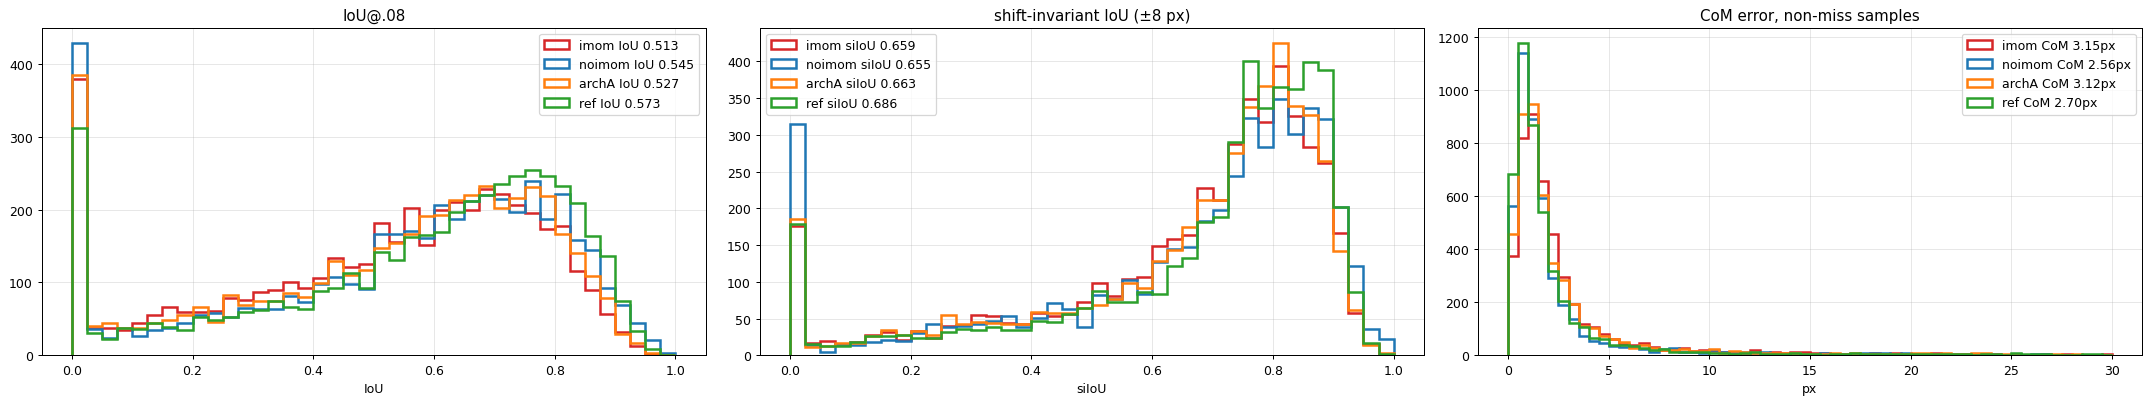

In [5]:
# per split for the pair, sorted by the miss-rate difference
G = pd.concat({r: TX[r].groupby(["box", "split"]).agg(n=("iou", "size"), iou=("iou", "mean"), si=("si_iou", "mean"), miss=("cls", lambda c: (c == "miss").mean()),
                                                         disp=("cls", lambda c: (c == "displaced").mean()), good=("cls", lambda c: (c == "good").mean())) for r in PAIR}, axis=1)
G["Δmiss"] = G["noimom", "miss"] - G["imom", "miss"]; G["Δiou"] = G["noimom", "iou"] - G["imom", "iou"]
G = G.drop(columns=("noimom", "n")).sort_values("Δmiss", ascending=False)
print("T3 · per split, imom vs noimom (sorted by Δmiss = noimom − imom)"); display(G.round(3))

# paired transitions: imom class -> noimom class
pt = pd.crosstab(TX["imom"].cls.rename("imom"), TX["noimom"].cls.rename("noimom"), margins=True)
print("T4 · paired class transitions, all samples (rows imom, cols noimom)"); display(pt)
cc = (TX["imom"].box == "cardboard") & (TX["imom"].split == "cube")
print("T4b · cardboard / cube"); display(pd.crosstab(TX["imom"].cls[cc].rename("imom"), TX["noimom"].cls[cc].rename("noimom"), margins=True))

fig, axs = plt.subplots(1, 3, figsize=(24, 4.6))
for r in GRID:
    t = TX[r]
    axs[0].hist(t.iou, np.linspace(0, 1, 41), histtype="step", lw=2, color=COL[r], label=f"{r} IoU {t.iou.mean():.3f}")
    axs[1].hist(t.si_iou, np.linspace(0, 1, 41), histtype="step", lw=2, color=COL[r], label=f"{r} siIoU {t.si_iou.mean():.3f}")
    axs[2].hist(t.com_err[t.cls != "miss"], np.linspace(0, 30, 61), histtype="step", lw=2, color=COL[r], label=f"{r} CoM {t.com_err[t.cls != 'miss'].mean():.2f}px")
axs[0].set(title="IoU@.08", xlabel="IoU"); axs[1].set(title="shift-invariant IoU (±8 px)", xlabel="siIoU"); axs[2].set(title="CoM error, non-miss samples", xlabel="px")
for ax in axs: ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 3 · calibration / commitment
Σp / true area (soft mass ratio), max prob, how often a run has a sub-threshold blob (max p < .08 but Σp ≥ 10% of true area), and where noimom's mass sits on its misses (IoU at lower thresholds, fraction of mass inside the true mask). Also the best global threshold per run: is noimom just calibrated lower?

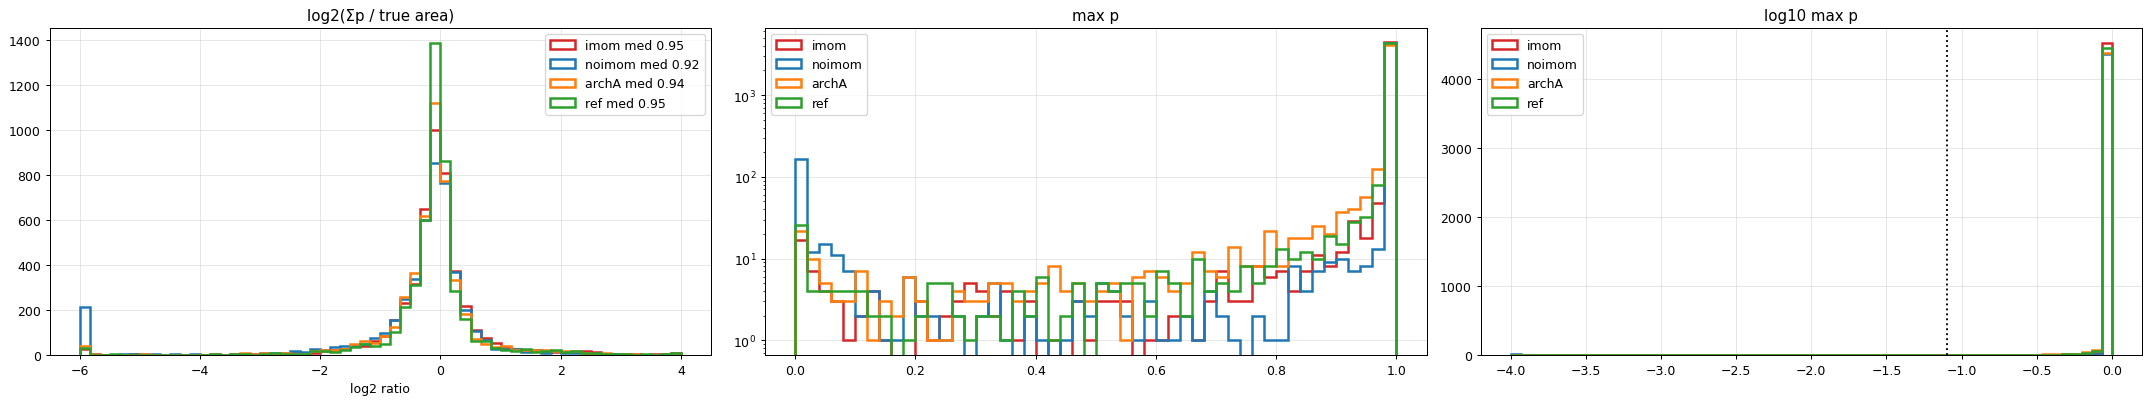

C1 · calibration


Σp/true med  Σp/true mean  max p med  max p<.08  max p<.08 & Σp≥.1·true  max p<.02  mass in true mask
overall          imom          0.952         1.135      1.000      0.007                     0.0      0.004              0.648
                 noimom        0.921         0.979      1.000      0.043                     0.0      0.035              0.702
                 archA         0.941         1.076      1.000      0.009                     0.0      0.005              0.662
                 ref           0.953         1.108      1.000      0.008                     0.0      0.006              0.704
cardboard / cube imom          0.973         0.958      1.000      0.000                     0.0      0.000              0.495
                 noimom        0.944         0.858      1.000      0.032                     0.0      0.027              0.615
                 archA         0.907         0.876      0.992      0.000                     0.0      0.000              0.569
                 ref           0.947         0.924      1.000      0.000                     0.0      0.000              0.653
two-object       imom          0.747         0.749      1.000      0.000                     0.0      0.000              0.487
                 noimom        0.685         0.693      1.000      0.000                     0.0      0.000              0.604
                 archA         0.743         0.714      0.992      0.006                     0.0      0.003              0.492
                 ref           0.814         0.807      1.000      0.000                     0.0      0.000              0.581

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(24, 4.6))
for r in GRID:
    t = TX[r]
    axs[0].hist(np.log2((t.sum_p / t.true_area).clip(1 / 64, 16)), np.linspace(-6, 4, 61), histtype="step", lw=2, color=COL[r], label=f"{r} med {np.median(t.sum_p / t.true_area):.2f}")
    axs[1].hist(t.max_p, np.linspace(0, 1, 51), histtype="step", lw=2, color=COL[r], label=r)
    axs[2].hist(np.log10(t.max_p.clip(1e-4)), np.linspace(-4, 0, 61), histtype="step", lw=2, color=COL[r], label=r)
axs[0].set(title="log2(Σp / true area)", xlabel="log2 ratio"); axs[1].set(title="max p", yscale="log"); axs[2].set(title="log10 max p"); axs[2].axvline(np.log10(THR), c="k", ls=":")
for ax in axs: ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

def calib(r, sel):
    t, p, y = TX[r][sel], PR[r][sel], YT[sel]
    sub = (t.max_p < THR); nontriv = t.sum_p >= .1 * t.true_area
    mass_in = np.array([p[i][y[i]].sum() / max(p[i].sum(), 1e-9) for i in range(len(p))])
    return {"Σp/true med": (t.sum_p / t.true_area).median(), "Σp/true mean": (t.sum_p / t.true_area).mean(), "max p med": t.max_p.median(),
            "max p<.08": sub.mean(), "max p<.08 & Σp≥.1·true": (sub & nontriv).mean(), "max p<.02": (t.max_p < .02).mean(), "mass in true mask": mass_in.mean()}
C1 = pd.DataFrame({(s, r): calib(r, TX[r].index.isin(SUBSETS[s](TX[r]).index))
                   for s in ["overall", "cardboard / cube", "two-object"] for r in GRID}).T
print("C1 · calibration"); display(C1.round(3))

In [7]:
def lowthr(r, sel):
    p, y = PR[r][sel], YT[sel]
    out = {}
    for th in (.08, .04, .02, .01, .005):
        b = p > th; out[f"IoU@{th}"] = ((b & y).reshape(len(p), -1).sum(1) / np.maximum((b | y).reshape(len(p), -1).sum(1), 1)).mean()
    out["mass in true mask"] = np.mean([p[i][y[i]].sum() / max(p[i].sum(), 1e-9) for i in range(len(p))])
    out["mass in true ±4px"] = np.mean([p[i][np.asarray(F.max_pool2d(torch.tensor(y[i], dtype=torch.float)[None], 9, 1, 4)[0]) > 0].sum() / max(p[i].sum(), 1e-9) for i in range(len(p))])
    out["Σp/true"] = np.mean(p.reshape(len(p), -1).sum(1) / y.reshape(len(y), -1).sum(1)); out["n"] = len(p)
    return out
nm = (TX["noimom"].cls == "miss").values; im = (TX["imom"].cls == "miss").values
C2 = pd.DataFrame({"noimom on noimom misses": lowthr("noimom", nm), "imom on the same samples": lowthr("imom", nm),
                   "imom on imom misses": lowthr("imom", im), "noimom on imom misses": lowthr("noimom", im)}).T
print("C2 · where is the probability mass on misses? (IoU at lower thresholds; mass fraction inside the true mask / dilated by 4 px)"); display(C2.round(3))

THS = np.array([.005, .01, .02, .04, .06, .08, .12, .2, .3, .5])
C3 = pd.DataFrame({r: {th: ((PR[r] > th) & YT).reshape(len(YT), -1).sum(1).__truediv__(np.maximum(((PR[r] > th) | YT).reshape(len(YT), -1).sum(1), 1)).mean() for th in THS} for r in GRID}).T
C3["best thr"] = C3[THS].idxmax(axis=1); C3["best IoU"] = C3[THS].max(axis=1)
print("C3 · mean IoU over all eval samples vs threshold"); display(C3.round(3))

C2 · where is the probability mass on misses? (IoU at lower thresholds; mass fraction inside the true mask / dilated by 4 px)


,IoU@0.08,IoU@0.04,IoU@0.02,IoU@0.01,IoU@0.005,mass in true mask,mass in true ±4px,Σp/true,n
noimom on noimom misses,0.002,0.006,0.008,0.010,0.013,0.115,0.222,0.007,244.0
imom on the same samples,0.084,0.088,0.090,0.094,0.095,0.161,0.411,1.183,244.0
imom on imom misses,0.001,0.002,0.004,0.009,0.012,0.133,0.248,0.015,42.0
noimom on imom misses,0.040,0.042,0.044,0.048,0.050,0.188,0.325,0.236,42.0


C3 · mean IoU over all eval samples vs threshold


,0.005,0.01,0.02,0.04,0.06,0.08,0.12,0.2,0.3,0.5,best thr,best IoU
imom,0.486,0.496,0.504,0.510,0.512,0.513,0.514,0.514,0.512,0.507,0.20,0.514
noimom,0.542,0.543,0.545,0.545,0.545,0.545,0.545,0.544,0.543,0.539,0.06,0.545
archA,0.499,0.508,0.516,0.523,0.526,0.527,0.529,0.529,0.527,0.519,0.20,0.529
ref,0.544,0.553,0.562,0.568,0.572,0.573,0.575,0.577,0.576,0.570,0.20,0.577


### 3b · does IoU@.08 reward noimom on easy samples while displaced blobs score ~0 anyway?
Paired per sample, binned by imom's class: mean ΔIoU (noimom − imom) and each bin's contribution to the overall difference.

In [8]:
j = pd.DataFrame(dict(cls_imom=TX["imom"].cls, cls_noimom=TX["noimom"].cls, iou_i=TX["imom"].iou, iou_n=TX["noimom"].iou, si_i=TX["imom"].si_iou, si_n=TX["noimom"].si_iou, group=META.group))
for name, sel in [("all", j.index == j.index), ("ID", j.group.isin(["id", "multiple"])), ("OOD", j.group.isin(OOD))]:
    jj = j[sel]; tot = (jj.iou_n - jj.iou_i).sum()
    b = jj.groupby("cls_imom").apply(lambda g: pd.Series(dict(n=len(g), iou_imom=g.iou_i.mean(), iou_noimom=g.iou_n.mean(), dIoU=(g.iou_n - g.iou_i).mean(),
                                                                share_of_total=(g.iou_n - g.iou_i).sum() / tot, dSI=(g.si_n - g.si_i).mean())), include_groups=False)
    print(f"C4 · {name}: ΔIoU total {tot / len(jj):+.3f} per sample; binned by imom's class"); display(b.round(3))
jj = j[j.group.isin(["id", "multiple"])]
print("C4b · ID, binned by noimom's class"); display(jj.groupby("cls_noimom").apply(lambda g: pd.Series(dict(n=len(g), iou_imom=g.iou_i.mean(), iou_noimom=g.iou_n.mean(), dIoU=(g.iou_n - g.iou_i).mean())), include_groups=False).round(3))

C4 · all: ΔIoU total +0.032 per sample; binned by imom's class


,n,iou_imom,iou_noimom,dIoU,share_of_total,dSI
cls_imom,,,,,,
displaced,399.0,0.113,0.227,0.114,0.309,-0.087
good,2813.0,0.687,0.694,0.007,0.130,0.000
miss,42.0,0.001,0.040,0.039,0.011,0.103
other,1406.0,0.295,0.352,0.057,0.549,0.007


C4 · ID: ΔIoU total +0.048 per sample; binned by imom's class


,n,iou_imom,iou_noimom,dIoU,share_of_total,dSI
cls_imom,,,,,,
displaced,117.0,0.149,0.316,0.167,0.164,-0.063
good,1833.0,0.712,0.736,0.025,0.379,0.016
miss,2.0,0.000,0.334,0.334,0.006,0.446
other,549.0,0.339,0.438,0.099,0.452,0.034


C4 · OOD: ΔIoU total +0.006 per sample; binned by imom's class


,n,iou_imom,iou_noimom,dIoU,share_of_total,dSI
cls_imom,,,,,,
displaced,221.0,0.074,0.145,0.071,1.750,-0.102
good,519.0,0.640,0.595,-0.045,-2.613,-0.046
miss,35.0,0.002,0.029,0.027,0.107,0.099
other,632.0,0.225,0.250,0.025,1.756,-0.003


C4b · ID, binned by noimom's class


,n,iou_imom,iou_noimom,dIoU
cls_noimom,,,,
displaced,63.0,0.264,0.153,-0.111
good,2005.0,0.671,0.738,0.067
miss,15.0,0.079,0.008,-0.071
other,418.0,0.348,0.333,-0.014


## 4 · encoder vs decoder / loss
Load both ep200 checkpoints; fp32 forward on 2000 train + every single-object eval sample. Probes u (256) → true CoM (ridge, 1-hidden-layer MLP, 5-NN), fit on train samples, scored on held-out eval positions, incl. the samples noimom misses and imom displaces. Compare with the decoded mask's own CoM error on the same samples, and the decoder's logit statistics inside vs outside the true mask.

In [9]:
SD = {r: torch.load(ROOT / f"runs/{GRID[r]}/checkpoints/ep200-ba2000-rank0.pt", weights_only=False, map_location="cpu")["state"]["model"] for r in PAIR}
samples, idxs = D9.load_splits(); metas = list(samples.values())
NAMES = sorted({m["box"] for m in metas})
KW = ("freq_cls", "laser_cls", "freq_layers", "laser_layers", "band_proj", "laser_proj", "band_v", "laser_v", "rope", "heads", "readout", "latent_dim", "d", "norm", "box_emb", "pos", "outline", "aux", "loss")
def build(r):
    sd = SD[r]; a = json.load(open(ROOT / "runs" / GRID[r] / "args.json")); K = sd["n_objects_head.2.weight"].shape[0] - 1
    assert sd["box_head.2.weight"].shape[0] == len(NAMES)
    info = dict(freq_range=(100.0, 1000.0), n_freqs=1170, n_laser_rows=10, n_laser_cols=10, n_channels=2, boxes=NAMES,
                cum_mean=sd["encoder.cum_mean"], cum_var=sd["encoder.cum_std"].pow(-2), objects=["a", "unseen"], n_objects=list(range(K + 1)))
    m = Transformer2(info, **{k: a[k] for k in KW}); m.load_state_dict(sd, strict=True); return m.eval().to(DEV)
M = {r: build(r) for r in PAIR}

tr = [(m["experiment"], int(m["sample_id"]) if m["sample_id"].isdigit() else -1, int(m["position_id"]), int(m["speaker"])) for m in (metas[i] for i in idxs["train"]) if m["n_objects"] == 1]
NTR = 2000
ev1 = META[META.nobj == 1]                                                         # every single-object eval sample (ID, unseen-position, OOD, control)
SEL = [("train", s) for s in (tr[i] for i in np.random.choice(len(tr), NTR, replace=False))] + [(g, (e, s, p, k)) for g, e, s, p, k in ev1[["group", "exp", "sid", "pos", "spk"]].itertuples(index=False)]
EVIDX = np.r_[[-1] * NTR, ev1.index.values]                                          # row in META / TX, -1 = train
GROUP = np.array([g for g, _ in SEL]); N = len(SEL)
print(N, "samples:", pd.Series(GROUP).value_counts().to_dict())

@torch.no_grad()
def forward_all(idx_batch):
    xs, bx = [], []
    for _, (exp, sid, pos, spk) in (SEL[i] for i in idx_batch):
        d = score.sample_dir(exp, sid, pos, spk); meta = D9.load_meta(d)
        s = D9.load_fft(d, meta, "tukey").abs(); xs.append((s / s.std()).float()); bx.append(NAMES.index(meta["box"]))
    batch = dict(fft=torch.stack(xs).to(DEV), box=torch.tensor(bx, device=DEV))
    return {r: {k: v.cpu() for k, v in (lambda o: dict(u=o["latent"], logits=o["mask_logits"]))(M[r](batch)).items()} for r in PAIR}
O = {r: {"u": [], "logits": []} for r in PAIR}
for i in range(0, N, 64):
    o = forward_all(np.arange(i, min(i + 64, N)))
    for r in PAIR:
        for k in O[r]: O[r][k].append(o[r][k])
O = {r: {k: torch.cat(v).numpy() for k, v in O[r].items()} for r in PAIR}
YS = np.stack([score.truth(*s, 64, 64) > .5 for _, s in SEL])
sig = lambda L: 1 / (1 + np.exp(-np.clip(L, -50, 50)))
# reproduces the saved eval outputs? (saved ones come from the training-time eval, autocast)
e = EVIDX >= 0
for r in PAIR:
    pf, ps = sig(O[r]["logits"][e]), PR[r][EVIDX[e]]
    i_f = ((pf > THR) & YS[e]).reshape(e.sum(), -1).sum(1) / np.maximum(((pf > THR) | YS[e]).reshape(e.sum(), -1).sum(1), 1)
    print(f"{r}: mean |Δp| {np.abs(pf - ps).mean():.2e}, max {np.abs(pf - ps).max():.3f}; IoU@.08 fp32 forward {i_f.mean():.4f} vs saved {TX[r].iou[EVIDX[e]].mean():.4f}")

2026_09_27_gastronorm_four_objs: 6155 samples


2026_10_05_green_plastic_four_objs: 5736 samples


2026_10_11_cardboard_four_objs: 7228 samples


split                                          samples    positions
-------------------------------------------  ---------  -----------
train                                            11219         3032
eval/gastro/vase                                   135           45
eval/gastro/candle                                 156           52
eval/gastro/cube                                   147           49
eval/gastro/cube-unseen-speaker-baseline           105           35
eval/gastro/cube-unseen-speaker-unseen              35           35
eval/gastro/soap-dispenser                         146           49
eval/gastro/cube-vase                               27            9
eval/gastro/two-cubes                               42           14
eval/gastro/cube-with-lid                           15            5
eval/gastro/cube-without-lid                        15            5
eval/gastro/cylinder-1000g                          27            9
eval/gastro/cylinder-500g                       

imom: mean |Δp| 9.72e-05, max 0.194; IoU@.08 fp32 forward 0.5281 vs saved 0.5280
noimom: mean |Δp| 7.66e-05, max 0.284; IoU@.08 fp32 forward 0.5591 vs saved 0.5588


In [10]:
from sklearn.linear_model import RidgeCV
from sklearn.neural_network import MLPRegressor
gy, gx = np.mgrid[:64, :64]
COM = np.stack([[(gy * y).sum() / y.sum(), (gx * y).sum() / y.sum()] for y in YS])     # (N,2) px
TRi = np.where(GROUP == "train")[0]
def sub(mask_meta): return np.where(e)[0][mask_meta[EVIDX[e]].values]
PSUB = {"id": sub(META.group == "id"), "unseen-pos": sub(META.group == "unseen-position"), "OOD": sub(META.group.isin(OOD)), "cardboard/cube": sub((META.box == "cardboard") & (META.split == "cube")),
        "noimom misses": sub(TX["noimom"].cls == "miss"), "imom displaced": sub(TX["imom"].cls == "displaced"), "noimom good": sub(TX["noimom"].cls == "good")}
print({k: len(v) for k, v in PSUB.items()})
def mask_com(r, ix):
    p = sig(O[r]["logits"][ix]); b = p > THR
    err = [np.linalg.norm([gy[b[j]].mean() - COM[i, 0], gx[b[j]].mean() - COM[i, 1]]) if b[j].any() else np.nan for j, i in enumerate(ix)]
    return np.nanmean(err), np.isnan(err).mean()
P4 = {}
for r in PAIR:
    Z = O[r]["u"]; Zs = (Z - Z[TRi].mean(0)) / (Z[TRi].std(0) + 1e-6)
    rid = RidgeCV(alphas=np.logspace(-2, 4, 13)).fit(Zs[TRi], COM[TRi])
    mlp_ = MLPRegressor(hidden_layer_sizes=(256,), alpha=1e-2, max_iter=600, early_stopping=True, random_state=0).fit(Zs[TRi], COM[TRi] / 64)
    for g, ix in PSUB.items():
        d = torch.cdist(torch.tensor(Zs[ix]), torch.tensor(Zs[TRi])); nn_ = d.topk(5, largest=False).indices.numpy()
        me, emp = mask_com(r, ix)
        P4[(g, r)] = {"n": len(ix), "ridge err px": np.linalg.norm(rid.predict(Zs[ix]) - COM[ix], axis=1).mean(), "MLP err px": np.linalg.norm(mlp_.predict(Zs[ix]) * 64 - COM[ix], axis=1).mean(),
                      "5-NN err px": np.linalg.norm(COM[TRi][nn_].mean(1) - COM[ix], axis=1).mean(), "decoded mask CoM err px (non-empty)": me, "decoded empty@.08": emp}
    P4[("train (fit)", r)] = {"ridge err px": np.linalg.norm(rid.predict(Zs[TRi]) - COM[TRi], axis=1).mean(), "MLP err px": np.linalg.norm(mlp_.predict(Zs[TRi]) * 64 - COM[TRi], axis=1).mean()}
P4 = pd.DataFrame(P4).T
print(f"P1 · probes u (256) → true CoM (px at 64×64), single-object; fit on {NTR} train samples, scored on held-out eval positions; vs the decoded mask's own CoM"); display(P4.round(2))

{'id': 2191, 'unseen-pos': 197, 'OOD': 1407, 'cardboard/cube': 221, 'noimom misses': 241, 'imom displaced': 393, 'noimom good': 3020}


/home/ethantu/workspace/good-vibrations/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (600) reached and the optimization hasn't converged yet.
  warnings.warn(


/home/ethantu/workspace/good-vibrations/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (600) reached and the optimization hasn't converged yet.
  warnings.warn(


P1 · probes u (256) → true CoM (px at 64×64), single-object; fit on 2000 train samples, scored on held-out eval positions; vs the decoded mask's own CoM


,,n,ridge err px,MLP err px,5-NN err px,decoded mask CoM err px (non-empty),decoded empty@.08
id,imom,2191.0,6.01,6.57,4.06,1.63,0.00
unseen-pos,imom,197.0,4.73,6.19,3.78,1.79,0.00
OOD,imom,1407.0,9.41,10.44,8.04,5.53,0.02
cardboard/cube,imom,221.0,8.38,7.61,8.04,3.54,0.00
noimom misses,imom,241.0,14.82,15.84,15.27,13.70,0.06
imom displaced,imom,393.0,11.30,11.91,11.63,10.13,0.00
noimom good,imom,3020.0,5.91,6.72,3.90,1.51,0.00
train (fit),imom,NaN,5.44,1.34,NaN,NaN,NaN
id,noimom,2191.0,8.28,7.66,4.59,1.30,0.00
unseen-pos,noimom,197.0,6.09,6.89,3.62,1.47,0.00


L1 · decoder logits inside the true mask, in a 4-px ring around it, and far away (logit(.08) = -2.44)


in mean  in std  in p50  ring(≤4px) mean  far mean  far std  max logit / sample (mean)  per-sample max logit std  frac in-px > logit(.08)  frac far-px > logit(.08)
id             imom      4.577   5.827   5.707           -9.860   -14.169    2.717                     10.864                     2.577                    0.865                     0.000
               noimom    6.901   9.361  10.181          -26.268   -16.939    5.740                     15.372                     2.768                    0.859                     0.000
unseen-pos     imom      2.658   6.331   4.151          -10.344   -14.129    2.584                     10.297                     1.794                    0.773                     0.000
               noimom    4.072  11.628   7.961          -24.895   -16.724    5.274                     15.566                     1.821                    0.763                     0.000
OOD            imom     -2.688   8.903  -2.589          -10.412   -14.301    3.112                      8.163                     3.922                    0.496                     0.003
               noimom   -5.986  15.819  -7.059          -24.666   -16.910    5.440                     10.833                     7.943                    0.445                     0.001
cardboard/cube imom     -1.365   6.545  -0.484           -9.729   -14.725    2.974                      7.056                     1.879                    0.581                     0.001
               noimom   -0.975  13.176   2.156          -22.039   -16.573    4.690                     12.055                     5.030                    0.615                     0.001
noimom misses  imom    -11.280   4.980 -12.294          -11.431   -14.408    3.537                      4.129                     3.489                    0.074                     0.006
               noimom  -18.254   6.736 -16.774          -18.825   -16.701    4.631                     -5.079                     3.150                    0.003                     0.000

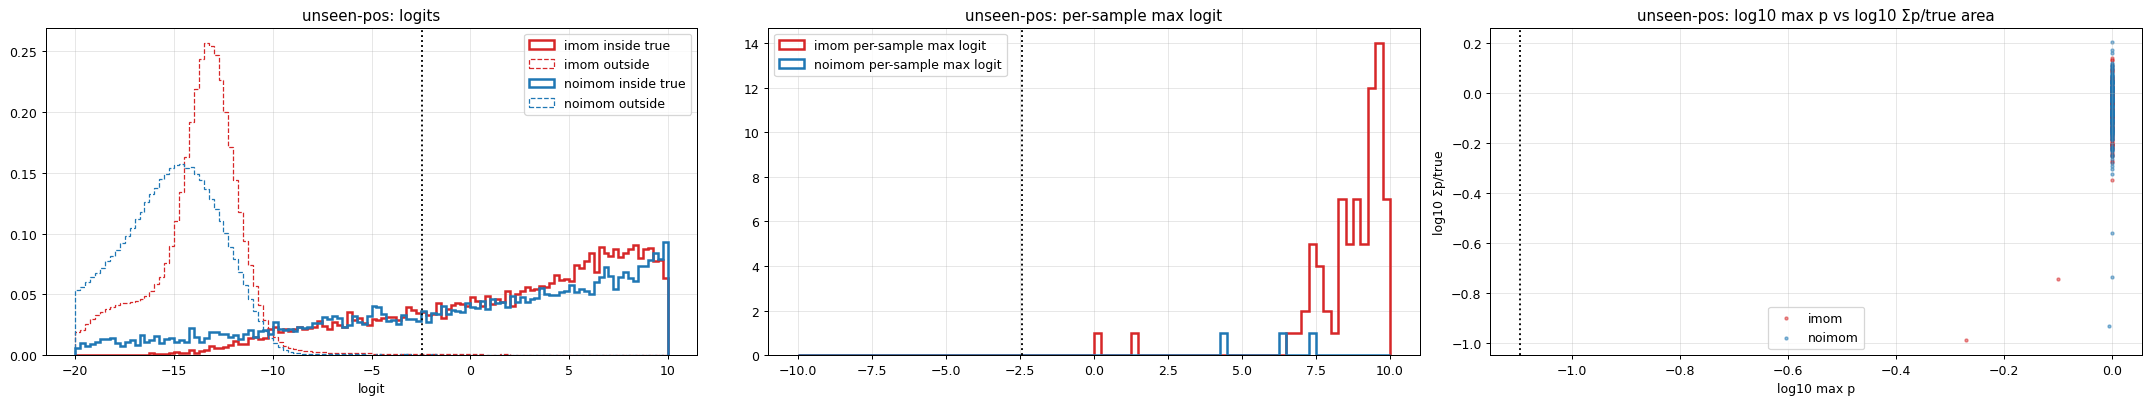

In [11]:
def logit_stats(r, ix):
    L, y = O[r]["logits"][ix], YS[ix]
    ring = np.stack([np.asarray(F.max_pool2d(torch.tensor(t, dtype=torch.float)[None], 9, 1, 4)[0]) > 0 for t in y]) & ~y
    far = ~y & ~ring
    return {"in mean": L[y].mean(), "in std": L[y].std(), "in p50": np.median(L[y]), "ring(≤4px) mean": L[ring].mean(), "far mean": L[far].mean(), "far std": L[far].std(),
            "max logit / sample (mean)": L.reshape(len(L), -1).max(1).mean(), "per-sample max logit std": L.reshape(len(L), -1).max(1).std(),
            "frac in-px > logit(.08)": (L[y] > np.log(THR / (1 - THR))).mean(), "frac far-px > logit(.08)": (L[far] > np.log(THR / (1 - THR))).mean()}
L1 = pd.DataFrame({(g, r): logit_stats(r, PSUB[g]) for g in ["id", "unseen-pos", "OOD", "cardboard/cube", "noimom misses"] for r in PAIR}).T
print(f"L1 · decoder logits inside the true mask, in a 4-px ring around it, and far away (logit(.08) = {np.log(THR / (1 - THR)):.2f})"); display(L1.round(3))

fig, axs = plt.subplots(1, 3, figsize=(24, 4.6))
for r in PAIR:
    L, y = O[r]["logits"][PSUB["unseen-pos"]], YS[PSUB["unseen-pos"]]
    axs[0].hist(L[y], np.linspace(-20, 10, 121), histtype="step", lw=2, color=COL[r], density=True, label=f"{r} inside true")
    axs[0].hist(L[~y], np.linspace(-20, 10, 121), histtype="step", lw=1, ls="--", color=COL[r], density=True, label=f"{r} outside")
    axs[1].hist(L.reshape(len(L), -1).max(1), np.linspace(-10, 10, 81), histtype="step", lw=2, color=COL[r], label=f"{r} per-sample max logit")
    ps = sig(L); axs[2].scatter(np.log10(ps.reshape(len(L), -1).max(1)), np.log10(ps.reshape(len(L), -1).sum(1) / y.reshape(len(y), -1).sum(1)), s=6, alpha=.5, color=COL[r], label=r)
for ax in axs[:2]: ax.axvline(np.log(THR / (1 - THR)), c="k", ls=":")
axs[0].set(title="unseen-pos: logits", xlabel="logit"); axs[1].set(title="unseen-pos: per-sample max logit"); axs[2].set(title="unseen-pos: log10 max p vs log10 Σp/true area", xlabel="log10 max p", ylabel="log10 Σp/true")
axs[2].axvline(np.log10(THR), c="k", ls=":")
for ax in axs: ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 4b · which weights differ
The two runs share init seed and data order, so parameters are roughly comparable. Per-module relative difference ‖W_noimom − W_imom‖ / ‖W_imom‖, norms of each, and the decoder output bias.

In [12]:
def group_of(k):
    p = k.split(".")
    if p[0] == "encoder": return ".".join(p[:3]) if p[1] in ("freq_enc", "laser_enc") else ".".join(p[:2])
    if p[0] == "decoder": return ".".join(p[:3]) if p[1] == "ups" else ".".join(p[:2])
    return p[0]
W = {}
for k in SD["imom"]:
    a, b = SD["imom"][k].float(), SD["noimom"][k].float()
    if not torch.is_floating_point(SD["imom"][k]) or k.endswith(("cum_mean", "cum_std")) or "running" in k: continue
    g = group_of(k); w = W.setdefault(g, dict(n=0, norm_imom=0., norm_noimom=0., diff=0.))
    w["n"] += a.numel(); w["norm_imom"] += a.pow(2).sum().item(); w["norm_noimom"] += b.pow(2).sum().item(); w["diff"] += (a - b).pow(2).sum().item()
W = pd.DataFrame(W).T; W[["norm_imom", "norm_noimom", "diff"]] = W[["norm_imom", "norm_noimom", "diff"]] ** .5
W["rel diff"] = W["diff"] / W.norm_imom; W["norm ratio n/i"] = W.norm_noimom / W.norm_imom
print("L2 · per-module parameter norms and differences"); display(W.round(3))
print("decoder.conv3 bias (output logit offset):", {r: SD[r]["decoder.conv3.bias"].tolist() for r in PAIR})
print("u_norm gain mean / bias mean:", {r: (SD[r]["encoder.laser_enc.u_norm.weight"].abs().mean().item(), SD[r]["encoder.laser_enc.u_norm.bias"].mean().item()) for r in PAIR})

L2 · per-module parameter norms and differences


,n,norm_imom,norm_noimom,diff,rel diff,norm ratio n/i
encoder.freq_enc.read_w,294912.0,27.731,27.684,2.821,0.102,0.998
encoder.freq_enc.read_b,128.0,0.554,0.554,0.008,0.015,1.000
encoder.freq_enc.embed,16768.0,6.596,6.575,0.403,0.061,0.997
encoder.freq_enc.freqs,793088.0,50.793,50.669,4.047,0.080,0.998
encoder.freq_enc.read_norm,256.0,11.295,11.298,0.071,0.006,1.000
encoder.laser_enc.read_w,3276800.0,92.584,92.422,10.623,0.115,0.998
encoder.laser_enc.read_b,256.0,0.796,0.796,0.016,0.020,0.999
encoder.laser_enc.lasers,793088.0,51.067,50.849,5.525,0.108,0.996
encoder.laser_enc.read_norm,256.0,11.308,11.304,0.056,0.005,1.000
encoder.laser_enc.u_norm,512.0,16.094,16.132,0.104,0.006,1.002


decoder.conv3 bias (output logit offset): {'imom': [-0.04272502660751343], 'noimom': [-0.0226296316832304]}
u_norm gain mean / bias mean: {'imom': (1.0058438777923584, 2.921969826275017e-05), 'noimom': (1.0082329511642456, 3.745394496945664e-05)}


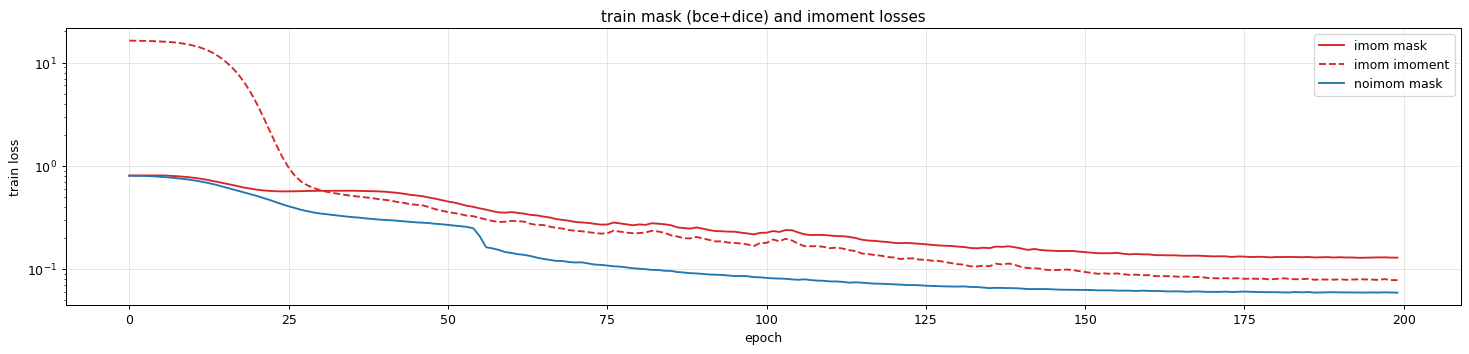

{'imom': {'total': np.float64(0.208812), 'mask': np.float64(0.129486), 'imoment': np.float64(0.078848)}, 'noimom': {'total': np.float64(0.05956), 'mask': np.float64(0.059352), 'imoment': None}}


In [13]:
LOG = {}
for r in PAIR:
    txt = (ROOT / "runs" / GRID[r] / "logs-rank0.txt").read_text()
    LOG[r] = {k: np.array([float(v) for v in re.findall(rf"Train loss/train/{k}: ([0-9.eE+-]+)", txt)]) for k in ("total", "mask", "imoment")}
fig, ax = plt.subplots(1, 1, figsize=(20, 4))
for r in PAIR:
    for k, ls in [("mask", "-"), ("imoment", "--")]:
        if len(LOG[r][k]): ax.plot(LOG[r][k].reshape(-1, 10).mean(1), ls, color=COL[r], label=f"{r} {k}")
ax.set(xlabel="epoch", ylabel="train loss", yscale="log", title="train mask (bce+dice) and imoment losses"); ax.legend(); ax.grid(alpha=.3); plt.show()
print({r: {k: (v.reshape(-1, 10).mean(1)[-5:].mean() if len(v) else None) for k, v in LOG[r].items()} for r in PAIR})

## 5 · summary
**Sample 003091-1** (cardboard/cube, pos 3091, spk 1; true area 41 px). imom draws a full, confident blob of the right size (Σp 43, 55 px above .08) about 5 px to the right, so IoU 0 and only 0.1% of its mass lands on the object. noimom draws nothing: max p .002, Σp 0.016. archA (.70) and ref (.46) hit it. At the same position with speakers 3 and 5, noimom draws a thin blob that is also shifted right (spk 7 is not in eval). The location estimate is off for every speaker; imom commits to it and noimom does not.

**Taxonomy** (miss / displaced / good, all samples): imom .009 / .086 / .604, noimom .052 / .043 / .662. On **cardboard/cube** (n=221): imom 0 / .344 / .335, noimom .032 / .176 / .543. The claim that noimom's errors are mostly no blob is **not** true for cardboard cube: only 7 of its 101 non-good samples are misses, while 39 are displaced and 55 are other. noimom's misses come from OOD splits: vase-laser-shifted-3/4 (83% miss; imom displaced 71%), cylinder-100g/200g, and cube-unseen-speaker-unseen. Two-object: imom 0 / .019 / .135, noimom .010 / .003 / .206. CoM error on non-miss samples is lower for noimom (2.56 vs 3.15 px overall; 2.55 vs 3.54 on cardboard cube).

**Blob in the wrong spot metric.** Shift-invariant IoU (best IoU over shifts of ±8 px) is .659 for imom vs .655 for noimom overall, and .500 vs .468 on OOD. On this metric the IoU@.08 gap (.513 vs .545) disappears, and imom leads on OOD. "Shift gain" = siIoU − IoU (imom .146, noimom .110) measures how much of a run's error is pure displacement. The displaced rate and miss rate are also worth logging.

**Calibration.** noimom does **not** spread low, sub-threshold mass. The fraction of samples with max p < .08 but Σp ≥ 10% of the true area is 0 for every run. On its misses, Σp / true area is .007 and the max logit averages −5. IoU at a .005 threshold is still .013. The threshold sweep is flat (best .06, .545), so lowering the threshold recovers nothing. noimom's logits are much more saturated than imom's: inside the mask median +10 vs +5.7; in the 4 px ring −26 vs −10; far-field std 5.7 vs 2.7. A miss is a confident "no object", not hedging.

**Encoder vs decoder.** imom's u carries location *more* linearly (ridge u → CoM: ID 6.0 vs 8.3 px; 5-NN 4.1 vs 4.6). Yet noimom's decoded mask is better located (ID 1.30 vs 1.63 px). The u probe does not limit performance, and imom's centroid term shapes u without improving the output. On the samples noimom misses, **both** encoders are lost: the probe error is about 15–16 px in both runs, and imom's own blob there is 13.7 px from the object. imom's IoU on those samples is only .084. Weights: the init is shared (seed 42). The decoder changed most (relative diff .2–.4, largest in conv2/conv3, norm +4–6%); encoder blocks changed about .1. Train mask loss at the end: imom .129 vs noimom .059, so imom costs about 2× in BCE+Dice fit.

**Explanation.** When the location is unknown, BCE+Dice scores an empty map lower than a wrong blob. Both have dice ≈ 1, and the wrong blob adds false-positive BCE. So noimom learns to answer "nothing" with confidence on inputs it cannot place, mostly OOD laser/speaker shifts. imom's log-area term (0.1·|log Σp − log A|) makes an empty map very costly (about 0.78 for this sample), and its centroid term costs only about the size of the displacement. imom therefore always paints a blob of the right size, placed wherever the encoder's guess is. When that guess is wrong, the blob scores 0 at IoU@.08, the same as a miss. The hypothesis that IoU@.08 rewards noimom only on easy samples is partly right. Of noimom's +.048 ID gain, 38% comes from samples imom already gets right (sharper masks), 45% from "other", and 16% from imom-displaced samples that noimom fixes. Misses cost noimom almost nothing, because imom scores .08 on them. On OOD, noimom's net is +.006: it loses .045 on imom-good samples and gains on displaced ones. **What dropping imom loses:** a committed, roughly placed blob on hard/OOD inputs, visible only in siIoU and the miss rate. In exchange it gains about 2× better train fit and tighter, better-placed masks in distribution.

**Recommendations.** (1) Log siIoU ±8, miss rate and displaced rate next to IoU@.08, so that abstaining and displacing are not both scored 0. (2) Try an **area-only imom**: log-area term only, weight 0.1–0.3, or a one-sided hinge that applies only when Σp is below the true area. It should keep the anti-empty commitment without the centroid/covariance terms that cost ID fit. Do this only if commitment on OOD is wanted; abstention may be the more honest behaviour there.
